## 1. Загрузка и подготовка датасета `Heart_Disease_and_Hospitals.csv`.

In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

df = pd.read_csv('Heart_Disease_and_Hospitals.csv')
print(f"Исходный размер таблицы: {df.shape[0]} строк, {df.shape[1]} колонок")

feature_cols = ['age', 'blood_pressure', 'cholesterol', 'bmi', 'glucose_level']
target_col = 'heart_disease'

clean_df = df[feature_cols + [target_col]].dropna().reset_index(drop=True)

X = clean_df[feature_cols].values.astype(float)
y = clean_df[target_col].values.astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print(f"Данные готовы к работе:")
print(f"Обучающая выборка (пациентов): {X_train.shape[0]}")
print(f"Тестовая выборка (пациентов): {X_test.shape[0]}")
print(f"Признаки: {feature_cols}")
print(f"Распределение классов (болен/здоров): {np.bincount(y)}")

Исходный размер таблицы: 10000 строк, 15 колонок
Данные готовы к работе:
Обучающая выборка (пациентов): 7000
Тестовая выборка (пациентов): 3000
Признаки: ['age', 'blood_pressure', 'cholesterol', 'bmi', 'glucose_level']
Распределение классов (болен/здоров): [4993 5007]


## 2. Базовые структуры дерева: Узел (Node) и Лист (Leaf)

In [3]:
class Node:
    """Класс узла дерева, содержащий правило разбиения."""
    def __init__(self, index, t, true_branch, false_branch):
        self.index = index
        self.t = t
        self.true_branch = true_branch
        self.false_branch = false_branch

class Leaf:
    """Класс терминального листа дерева, возвращающий предсказание."""
    def __init__(self, data, labels):
        self.data = data
        self.labels = labels
        self.prediction = self.predict()

    def predict(self):
        classes = {}
        for label in self.labels:
            if label not in classes:
                classes[label] = 0
            classes[label] += 1

        return max(sorted(classes), key=classes.get)

print("Базовые классы Node и Leaf успешно определены.")

Базовые классы Node и Leaf успешно определены.


## 3. Реализация функции расчёта критерия Джини

In [4]:
def gini(labels):
    """
    Расчёт критерия неопределённости Джини для массива меток.

    Параметры:
        labels: массив или список меток целевой переменной (классов)
    Возвращает:
        float: значение критерия Джини от 0.0 (чистый узел) до 0.5 (максимальный хаос)
    """
    if len(labels) == 0:
        return 0.0

    classes = {}
    for label in labels:
        if label not in classes:
            classes[label] = 0
        classes[label] += 1

    impurity = 1.0
    total_objects = len(labels)

    for count in classes.values():
        prob = count / total_objects
        impurity -= prob ** 2

    return impurity

test_1 = [0, 0, 1, 1]
test_2 = [1, 1, 1, 1]
test_3 = [0, 0, 0, 1]

print(f"Тест 1 (50/50):           Gini = {gini(test_1):.4f} (Ожидается: 0.5000)")
print(f"Тест 2 (Все одного класса): Gini = {gini(test_2):.4f} (Ожидается: 0.0000)")
print(f"Тест 3 (Небольшой перекос): Gini = {gini(test_3):.4f} (Ожидается: 0.3750)")

Тест 1 (50/50):           Gini = 0.5000 (Ожидается: 0.5000)
Тест 2 (Все одного класса): Gini = 0.0000 (Ожидается: 0.0000)
Тест 3 (Небольшой перекос): Gini = 0.3750 (Ожидается: 0.3750)


## 4. Реализация функции расчёта прироста информации

In [5]:
def split(data, labels, column_index, t):
    """
    Разделяет данные и метки на две ветви по условию: признак <= t.
    """
    left_mask = data[:, column_index] <= t
    right_mask = data[:, column_index] > t

    true_data, false_data = data[left_mask], data[right_mask]
    true_labels, false_labels = labels[left_mask], labels[right_mask]

    return true_data, false_data, true_labels, false_labels


def gain(left_labels, right_labels, root_gini):
    """
    Расчёт прироста информации (Information Gain).

    Параметры:
        left_labels: метки объектов, ушедших в левую ветку (True)
        right_labels: метки объектов, ушедших в правую ветку (False)
        root_gini: значение критерия Джини исходного узла до разбиения
    """
    n_left = len(left_labels)
    n_right = len(right_labels)
    n_total = n_left + n_right

    if n_total == 0 or n_left == 0 or n_right == 0:
        return 0.0

    p_left = n_left / n_total
    p_right = n_right / n_total

    weighted_gini = p_left * gini(left_labels) + p_right * gini(right_labels)

    return root_gini - weighted_gini

root = [0, 0, 0, 1, 1, 1]
root_g = gini(root)

left_perfect = [0, 0, 0]
right_perfect = [1, 1, 1]
gain_perfect = gain(left_perfect, right_perfect, root_g)

left_useless = [0, 1]
right_useless = [0, 0, 1, 1]
gain_useless = gain(left_useless, right_useless, root_g)

print(f"Исходный Gini родителя: {root_g:.4f}")
print(f"Прирост при идеальном разбиении:  Gain = {gain_perfect:.4f} (Ожидается: 0.5000)")
print(f"Прирост при бесполезном разбиении: Gain = {gain_useless:.4f} (Ожидается: 0.0000)")

Исходный Gini родителя: 0.5000
Прирост при идеальном разбиении:  Gain = 0.5000 (Ожидается: 0.5000)
Прирост при бесполезном разбиении: Gain = 0.0000 (Ожидается: 0.0000)


## 5. Реализация критериев останова и алгоритма построения дерева

In [7]:
def find_best_split(data, labels, min_samples_leaf=1):
    """
    Поиск наилучшего признака и порога для разбиения узла.
    Учитывает критерий останова: min_samples_leaf.
    """
    root_gini = gini(labels)
    best_gain = 0.0
    best_t = None
    best_index = None

    n_features = data.shape[1]

    for index in range(n_features):
        values = np.unique(data[:, index])

        t_values = (values[:-1] + values[1:]) / 2.0

        for t in t_values:
            true_data, false_data, true_labels, false_labels = split(data, labels, index, t)

            if len(true_labels) < min_samples_leaf or len(false_labels) < min_samples_leaf:
                continue

            current_gain = gain(true_labels, false_labels, root_gini)

            if current_gain > best_gain + 1e-12:
                best_gain = current_gain
                best_t = t
                best_index = index

    return best_gain, best_t, best_index


def build_tree(data, labels, max_depth=None, min_samples_split=2, min_samples_leaf=1, depth=0):
    """
    Рекурсивная функция построения решающего дерева.
    """
    if max_depth is not None and depth >= max_depth:
        return Leaf(data, labels)

    if len(labels) < min_samples_split:
        return Leaf(data, labels)

    if gini(labels) == 0.0:
        return Leaf(data, labels)

    best_gain, t, index = find_best_split(data, labels, min_samples_leaf)

    if best_gain <= 0.0 or t is None:
        return Leaf(data, labels)

    true_data, false_data, true_labels, false_labels = split(data, labels, index, t)

    true_branch = build_tree(true_data, true_labels, max_depth, min_samples_split, min_samples_leaf, depth + 1)
    false_branch = build_tree(false_data, false_labels, max_depth, min_samples_split, min_samples_leaf, depth + 1)

    return Node(index, t, true_branch, false_branch)

print("Функции find_best_split и build_tree готовы.")

Функции find_best_split и build_tree готовы.


## 6. Функции применения дерева: классификация и визуализация

In [8]:
def classify_object(obj, node):
    """
    Рекурсивно спускает один объект по дереву решений до листа и возвращает диагноз.
    """
    if isinstance(node, Leaf):
        return node.prediction

    if obj[node.index] <= node.t:
        return classify_object(obj, node.true_branch)
    else:
        return classify_object(obj, node.false_branch)


def predict(data, tree):
    """
    Применяет дерево ко всему набору данных (массиву объектов)
    и возвращает список предсказаний.
    """
    return [classify_object(obj, tree) for obj in data]


def print_tree(node, spacing=""):
    """
    Рекурсивно распечатывает структуру дерева в читаемом текстовом виде.
    """
    if isinstance(node, Leaf):
        print(spacing + "Прогноз:", node.prediction)
        return

    feature_name = feature_cols[node.index] if 'feature_cols' in globals() else f"Признак {node.index}"
    print(spacing + f"{feature_name} (индекс {node.index}) <= {node.t:.4f}")

    print(spacing + '--> True:')
    print_tree(node.true_branch, spacing + "  ")

    print(spacing + '--> False:')
    print_tree(node.false_branch, spacing + "  ")

print("Функции classify_object, predict и print_tree успешно добавлены.")

Функции classify_object, predict и print_tree успешно добавлены.


## 7. Реализация функции вычисления метрики Accuracy

In [9]:
def accuracy_metric(actual, predicted):
    """
    Вычисляет долю правильных ответов (Accuracy).

    Параметры:
        actual: истинные метки классов (массив или список)
        predicted: предсказанные метки классов (массив или список)
    Возвращает:
        float: значение точности от 0.0 до 1.0
    """
    correct = 0
    total = len(actual)

    if total == 0:
        return 0.0

    for i in range(total):
        if actual[i] == predicted[i]:
            correct += 1

    return correct / float(total)

test_true = [0, 1, 0, 1]
test_pred = [0, 1, 1, 1]

acc_custom = accuracy_metric(test_true, test_pred)
acc_sklearn = accuracy_score(test_true, test_pred)

print(f"Наша функция accuracy:   {acc_custom:.4f}")
print(f"Функция из sklearn:      {acc_sklearn:.4f}")
print(f"Результаты совпали:      {acc_custom == acc_sklearn}")

Наша функция accuracy:   0.7500
Функция из sklearn:      0.7500
Результаты совпали:      True


## 8. Обучение самописного дерева и верификация через scikit-learn

In [14]:
X_sub = X[:1000]
y_sub = y[:1000]

X_train_sub, X_test_sub, y_train_sub, y_test_sub = train_test_split(
    X_sub, y_sub, test_size=0.3, random_state=42, stratify=y_sub
)

params = dict(max_depth=4, min_samples_split=10, min_samples_leaf=5)

my_tree = build_tree(X_train_sub, y_train_sub, **params)

sk_tree = DecisionTreeClassifier(criterion='gini', random_state=42, **params)
sk_tree.fit(X_train_sub, y_train_sub)

my_train_pred = np.array(predict(X_train_sub, my_tree))
my_test_pred = np.array(predict(X_test_sub, my_tree))

sk_train_pred = sk_tree.predict(X_train_sub)
sk_test_pred = sk_tree.predict(X_test_sub)

my_acc_train = accuracy_metric(y_train_sub, my_train_pred)
my_acc_test = accuracy_metric(y_test_sub, my_test_pred)

sk_acc_train = accuracy_score(y_train_sub, sk_train_pred)
sk_acc_test = accuracy_score(y_test_sub, sk_test_pred)

print("=" * 60)
print("РЕЗУЛЬТАТЫ СРАВНЕНИЯ МОДЕЛЕЙ")
print("=" * 60)
print(f"Самописное дерево:")
print(f"  Accuracy на обучении: {my_acc_train:.6f}")
print(f"  Accuracy на тесте:    {my_acc_test:.6f}")
print(f"\nМодель sklearn:")
print(f"  Accuracy на обучении: {sk_acc_train:.6f}")
print(f"  Accuracy на тесте:    {sk_acc_test:.6f}")

print("\n" + "-" * 60)
print("ПРОВЕРКА НА ПОЛНОЕ СОВПАДЕНИЕ:")
train_match = np.array_equal(my_train_pred, sk_train_pred)
test_match = np.array_equal(my_test_pred, sk_test_pred)
print(f"Предсказания на train совпали на 100%: {train_match}")
print(f"Предсказания на test совпали на 100%:  {test_match}")
print("-" * 60)

print("\nСтруктура первых уровней построенного дерева:")
print_tree(my_tree)

РЕЗУЛЬТАТЫ СРАВНЕНИЯ МОДЕЛЕЙ
Самописное дерево:
  Accuracy на обучении: 0.898571
  Accuracy на тесте:    0.870000

Модель sklearn:
  Accuracy на обучении: 0.898571
  Accuracy на тесте:    0.870000

------------------------------------------------------------
ПРОВЕРКА НА ПОЛНОЕ СОВПАДЕНИЕ:
Предсказания на train совпали на 100%: True
Предсказания на test совпали на 100%:  True
------------------------------------------------------------

Структура первых уровней построенного дерева:
bmi (индекс 3) <= 29.5403
--> True:
  glucose_level (индекс 4) <= 95.8069
  --> True:
    blood_pressure (индекс 1) <= 131.0825
    --> True:
      glucose_level (индекс 4) <= 57.0467
      --> True:
        Прогноз: 0
      --> False:
        Прогноз: 0
    --> False:
      cholesterol (индекс 2) <= 165.2610
      --> True:
        Прогноз: 0
      --> False:
        Прогноз: 1
  --> False:
    cholesterol (индекс 2) <= 197.7315
    --> True:
      cholesterol (индекс 2) <= 36.1473
      --> True:
        Пр

## 9. Анализ важности признаков

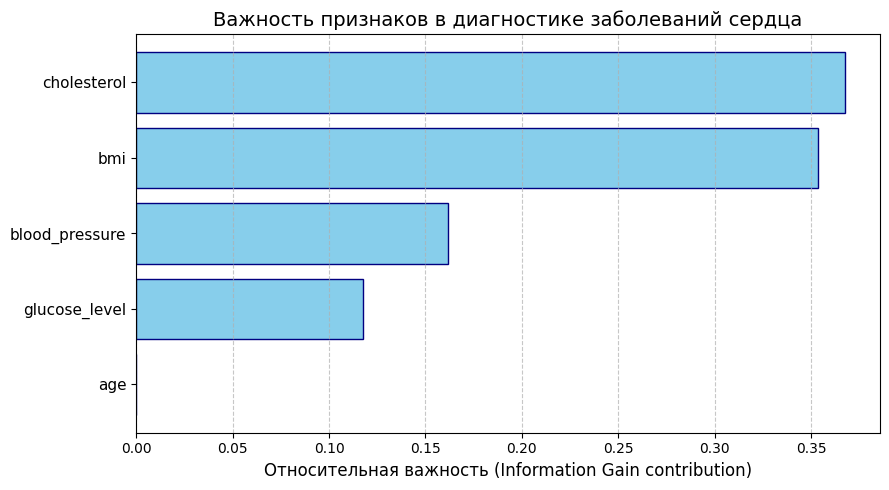

Признак 'cholesterol': важность = 0.3673
Признак 'bmi': важность = 0.3537
Признак 'blood_pressure': важность = 0.1615
Признак 'glucose_level': важность = 0.1175
Признак 'age': важность = 0.0000


In [11]:
import matplotlib.pyplot as plt

importances = sk_tree.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(9, 5))
plt.title("Важность признаков в диагностике заболеваний сердца", fontsize=14)
plt.barh(range(len(indices)), importances[indices], color='skyblue', edgecolor='navy')
plt.yticks(range(len(indices)), [feature_cols[i] for i in indices], fontsize=11)
plt.xlabel("Относительная важность (Information Gain contribution)", fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

for i in reversed(indices):
    print(f"Признак '{feature_cols[i]}': важность = {importances[i]:.4f}")

## 10. Исследование влияния гиперпараметров на переобучение дерева

In [12]:
experiments = [
    {"max_depth": 2, "min_samples_split": 2,  "min_samples_leaf": 1},
    {"max_depth": 3, "min_samples_split": 5,  "min_samples_leaf": 2},
    {"max_depth": 4, "min_samples_split": 10, "min_samples_leaf": 5},
    {"max_depth": 5, "min_samples_split": 10, "min_samples_leaf": 5},
    {"max_depth": 6, "min_samples_split": 15, "min_samples_leaf": 8},
]

table_rows = []

for exp in experiments:
    t_my = build_tree(X_train_sub, y_train_sub, **exp)
    pred_my = predict(X_test_sub, t_my)
    acc_my = accuracy_metric(y_test_sub, pred_my)

    t_sk = DecisionTreeClassifier(criterion='gini', random_state=42, **exp)
    t_sk.fit(X_train_sub, y_train_sub)
    pred_sk = t_sk.predict(X_test_sub)
    acc_sk = accuracy_score(y_test_sub, pred_sk)

    table_rows.append({
        "max_depth": exp["max_depth"],
        "min_samples_split": exp["min_samples_split"],
        "min_samples_leaf": exp["min_samples_leaf"],
        "Accuracy (Наше)": round(acc_my, 4),
        "Accuracy (sklearn)": round(acc_sk, 4),
        "100% совпадение": np.array_equal(pred_my, pred_sk)
    })

results_df = pd.DataFrame(table_rows)
display(results_df)

,max_depth,min_samples_split,min_samples_leaf,Accuracy (Наше),Accuracy (sklearn),100% совпадение
0,2,2,1,0.7133,0.7133,True
1,3,5,2,0.8867,0.8867,True
2,4,10,5,0.8700,0.8700,True
3,5,10,5,0.8667,0.8667,True
4,6,15,8,0.8833,0.8833,True
